# Studi Komparatif Empiris Model Generatif (AE, Sparse AE, VAE, Vanilla GAN, DCGAN, DDPM) & Pembuktian Batasan MLP Classifier

Notebook ini mengimpor modul terstandarisasi dari `src/` untuk:
1. Memverifikasi split data Fashion-MNIST (80% Train / 10% Val / 10% Test, `seed=42`).
2. Menjalankan atau memuat hasil pipeline lengkap (`python main.py`).
3. Menampilkan tabel komparasi metrik kuantitatif (`results/metrics.json`) serta kelima figur komparatif (`figures/`).

In [1]:
import json
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
import torch
from src.config import ExperimentConfig
from src.data.fashion_mnist import create_dataloaders
from src.utils.seed import get_device, set_seed

cfg = ExperimentConfig()
set_seed(cfg.seed)
device = get_device()
print(f"Device: {device} | Seed: {cfg.seed} | Batch Size: {cfg.batch_size}")
loaders = create_dataloaders(cfg)
print({k: len(v.dataset) for k, v in loaders.items()})

Device: cuda | Seed: 42 | Batch Size: 128
{'train': 56000, 'val': 7000, 'test': 7000}


In [2]:
# Jalankan pipeline penuh jika results/metrics.json belum tersedia
metrics_path = cfg.results_dir / "metrics.json"
if not metrics_path.exists():
    from main import main as run_full_pipeline
    run_full_pipeline()

metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
print("MLP Classifier Test Accuracy:", f"{metrics['mlp_proof']['test_accuracy']*100:.2f}%")
print("Frozen Decoder Test MSE:", f"{metrics['mlp_proof']['frozen_decoder_metrics']['mse']:.6f}")

MLP Classifier Test Accuracy: 90.03%
Frozen Decoder Test MSE: 0.015793


In [3]:
for model_name, vals in metrics["models"].items():
    print(
        f"{model_name:12s} | dim={str(vals['latent_dim']):5s} | "
        f"epoch_t={vals['epoch_time_s']:.2f}s | lat64={vals['latency_ms_mean']:.2f}ms | "
        f"MSE={vals['mse']} | PSNR={vals['psnr']} | SSIM={vals['ssim']} | FID={vals['fid']}"
    )

vanilla_ae   | dim=64    | epoch_t=1.10s | lat64=0.23ms | MSE=0.006463299971073866 | PSNR=23.013750076293945 | SSIM=0.8715124130249023 | FID=None
sparse_ae    | dim=64    | epoch_t=1.37s | lat64=0.32ms | MSE=0.008783548139035702 | PSNR=21.54901695251465 | SSIM=0.8290849924087524 | FID=None
vae          | dim=64    | epoch_t=1.50s | lat64=0.13ms | MSE=0.013083672150969505 | PSNR=19.678667068481445 | SSIM=0.777773380279541 | FID=89.69607136082392
vanilla_gan  | dim=64    | epoch_t=2.68s | lat64=0.27ms | MSE=None | PSNR=None | SSIM=None | FID=141.929666097694
dcgan        | dim=100   | epoch_t=6.02s | lat64=3.67ms | MSE=None | PSNR=None | SSIM=None | FID=15.158565782842807
ddpm         | dim=28x28 | epoch_t=22.40s | lat64=7441.52ms | MSE=None | PSNR=None | SSIM=None | FID=9.451571103484094


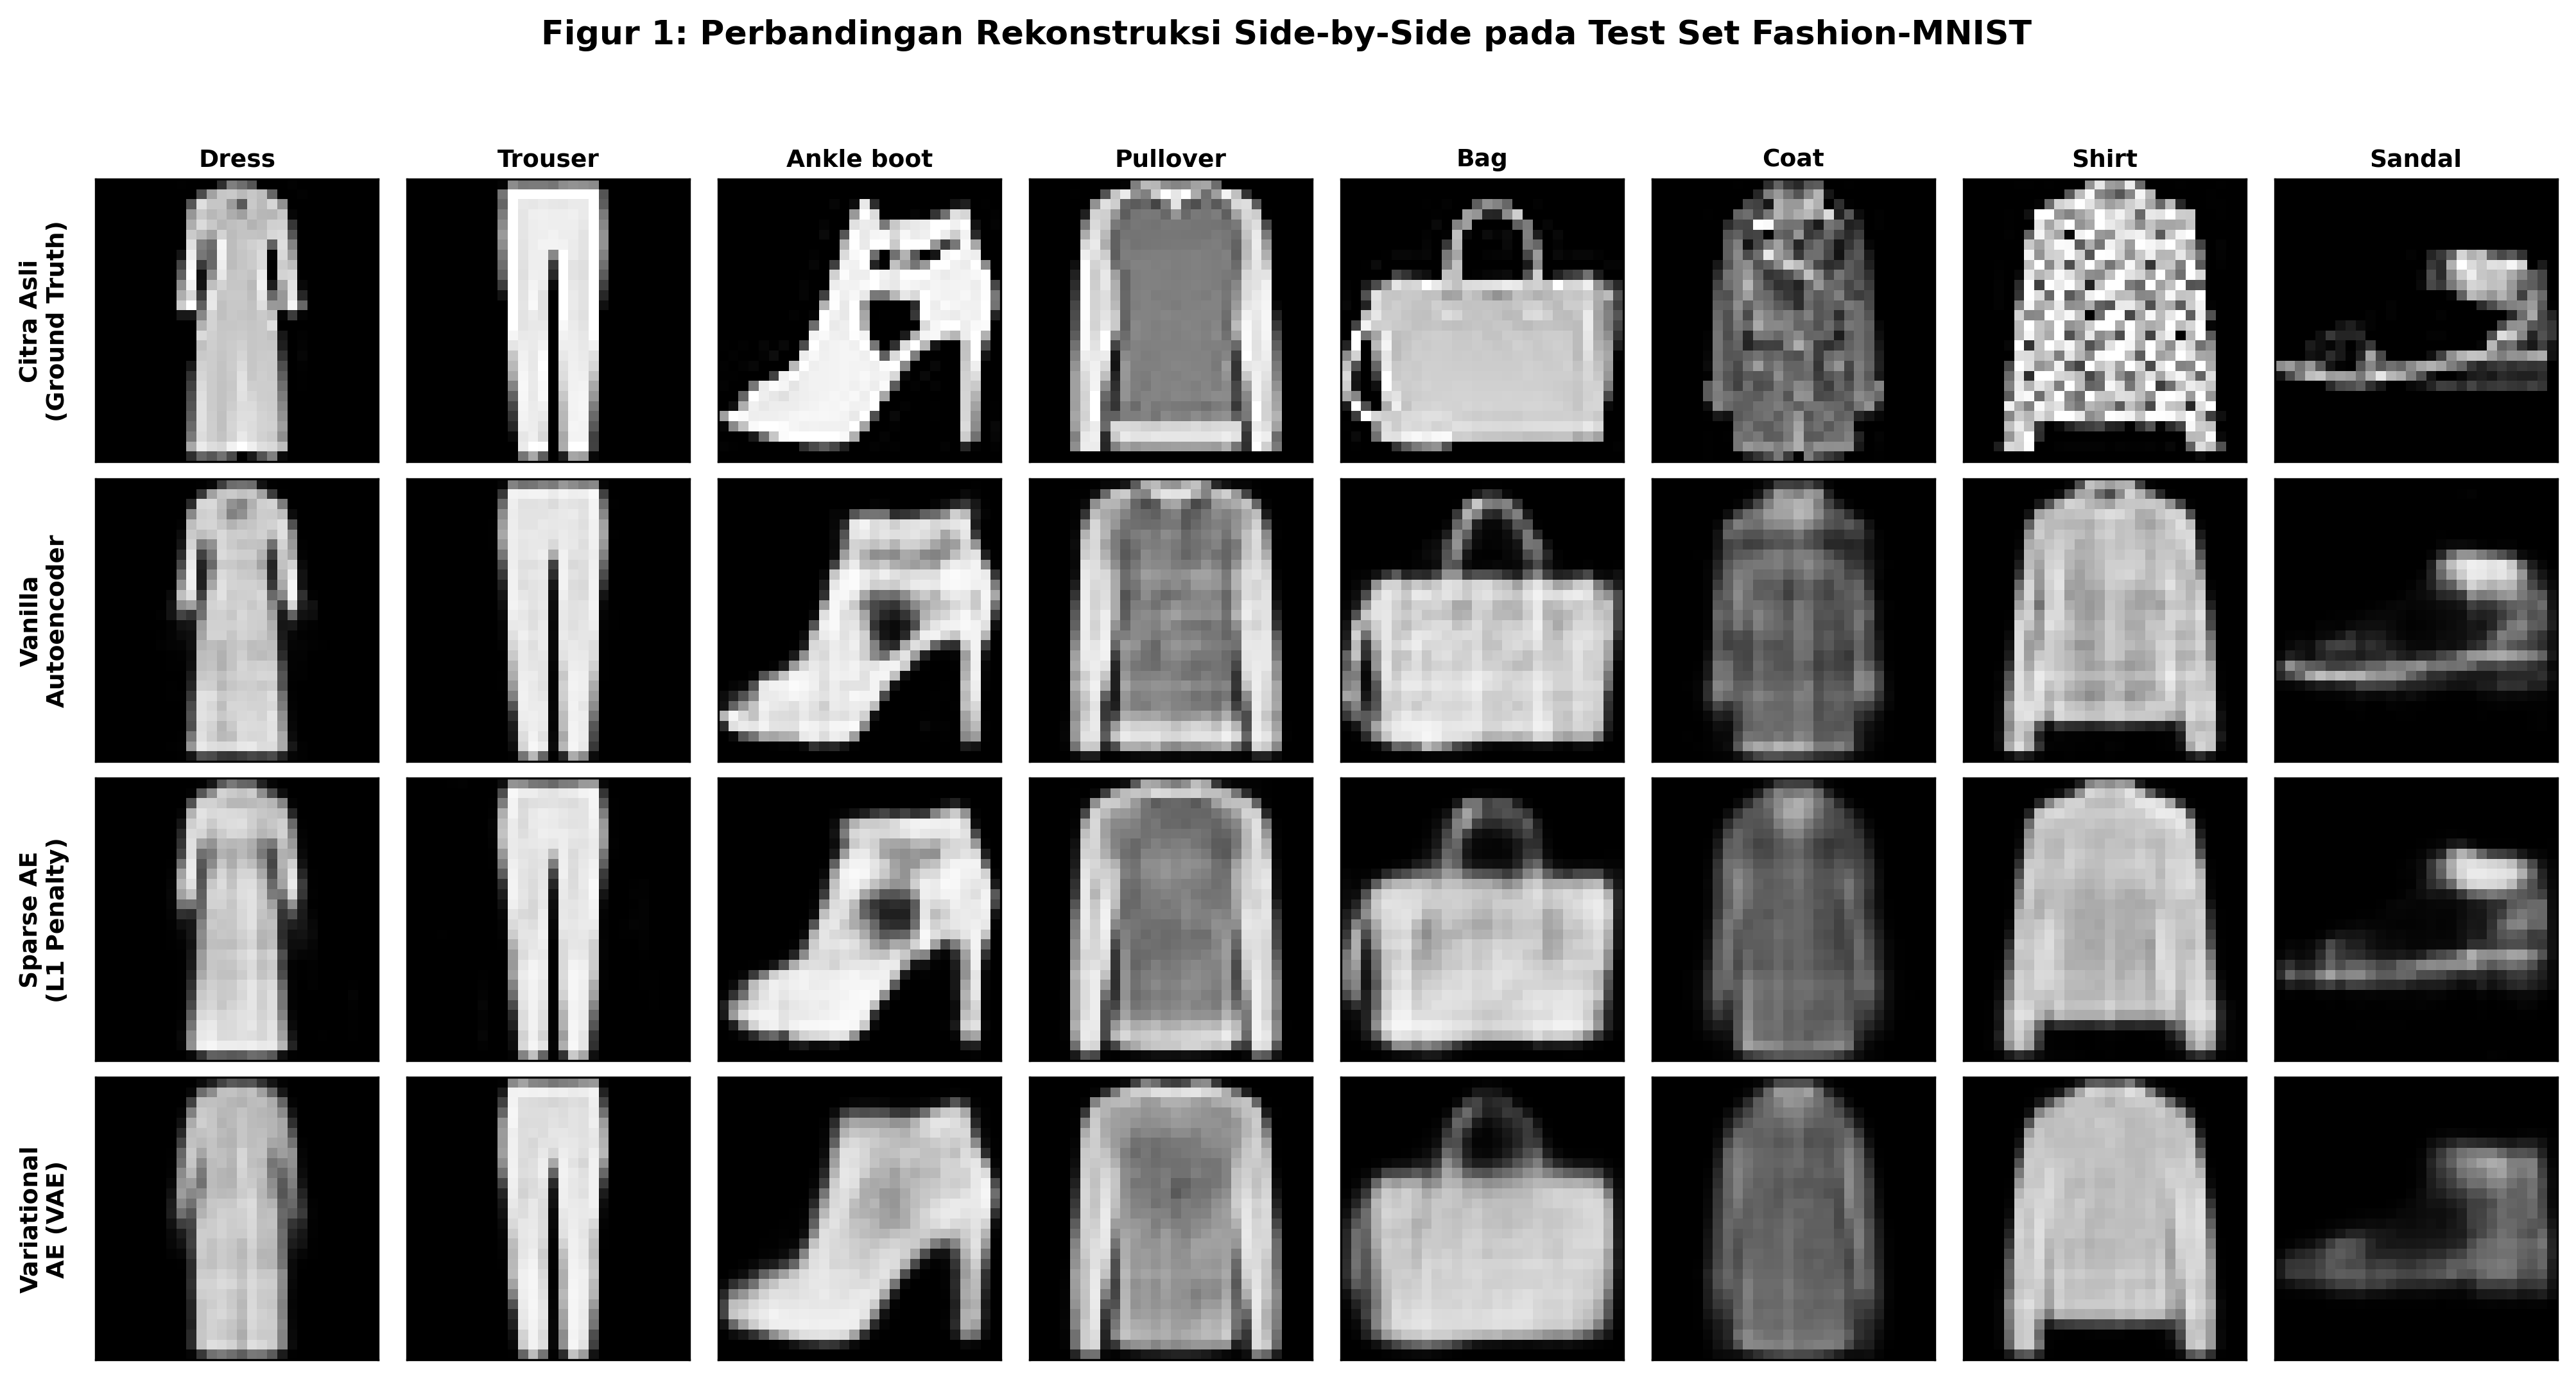

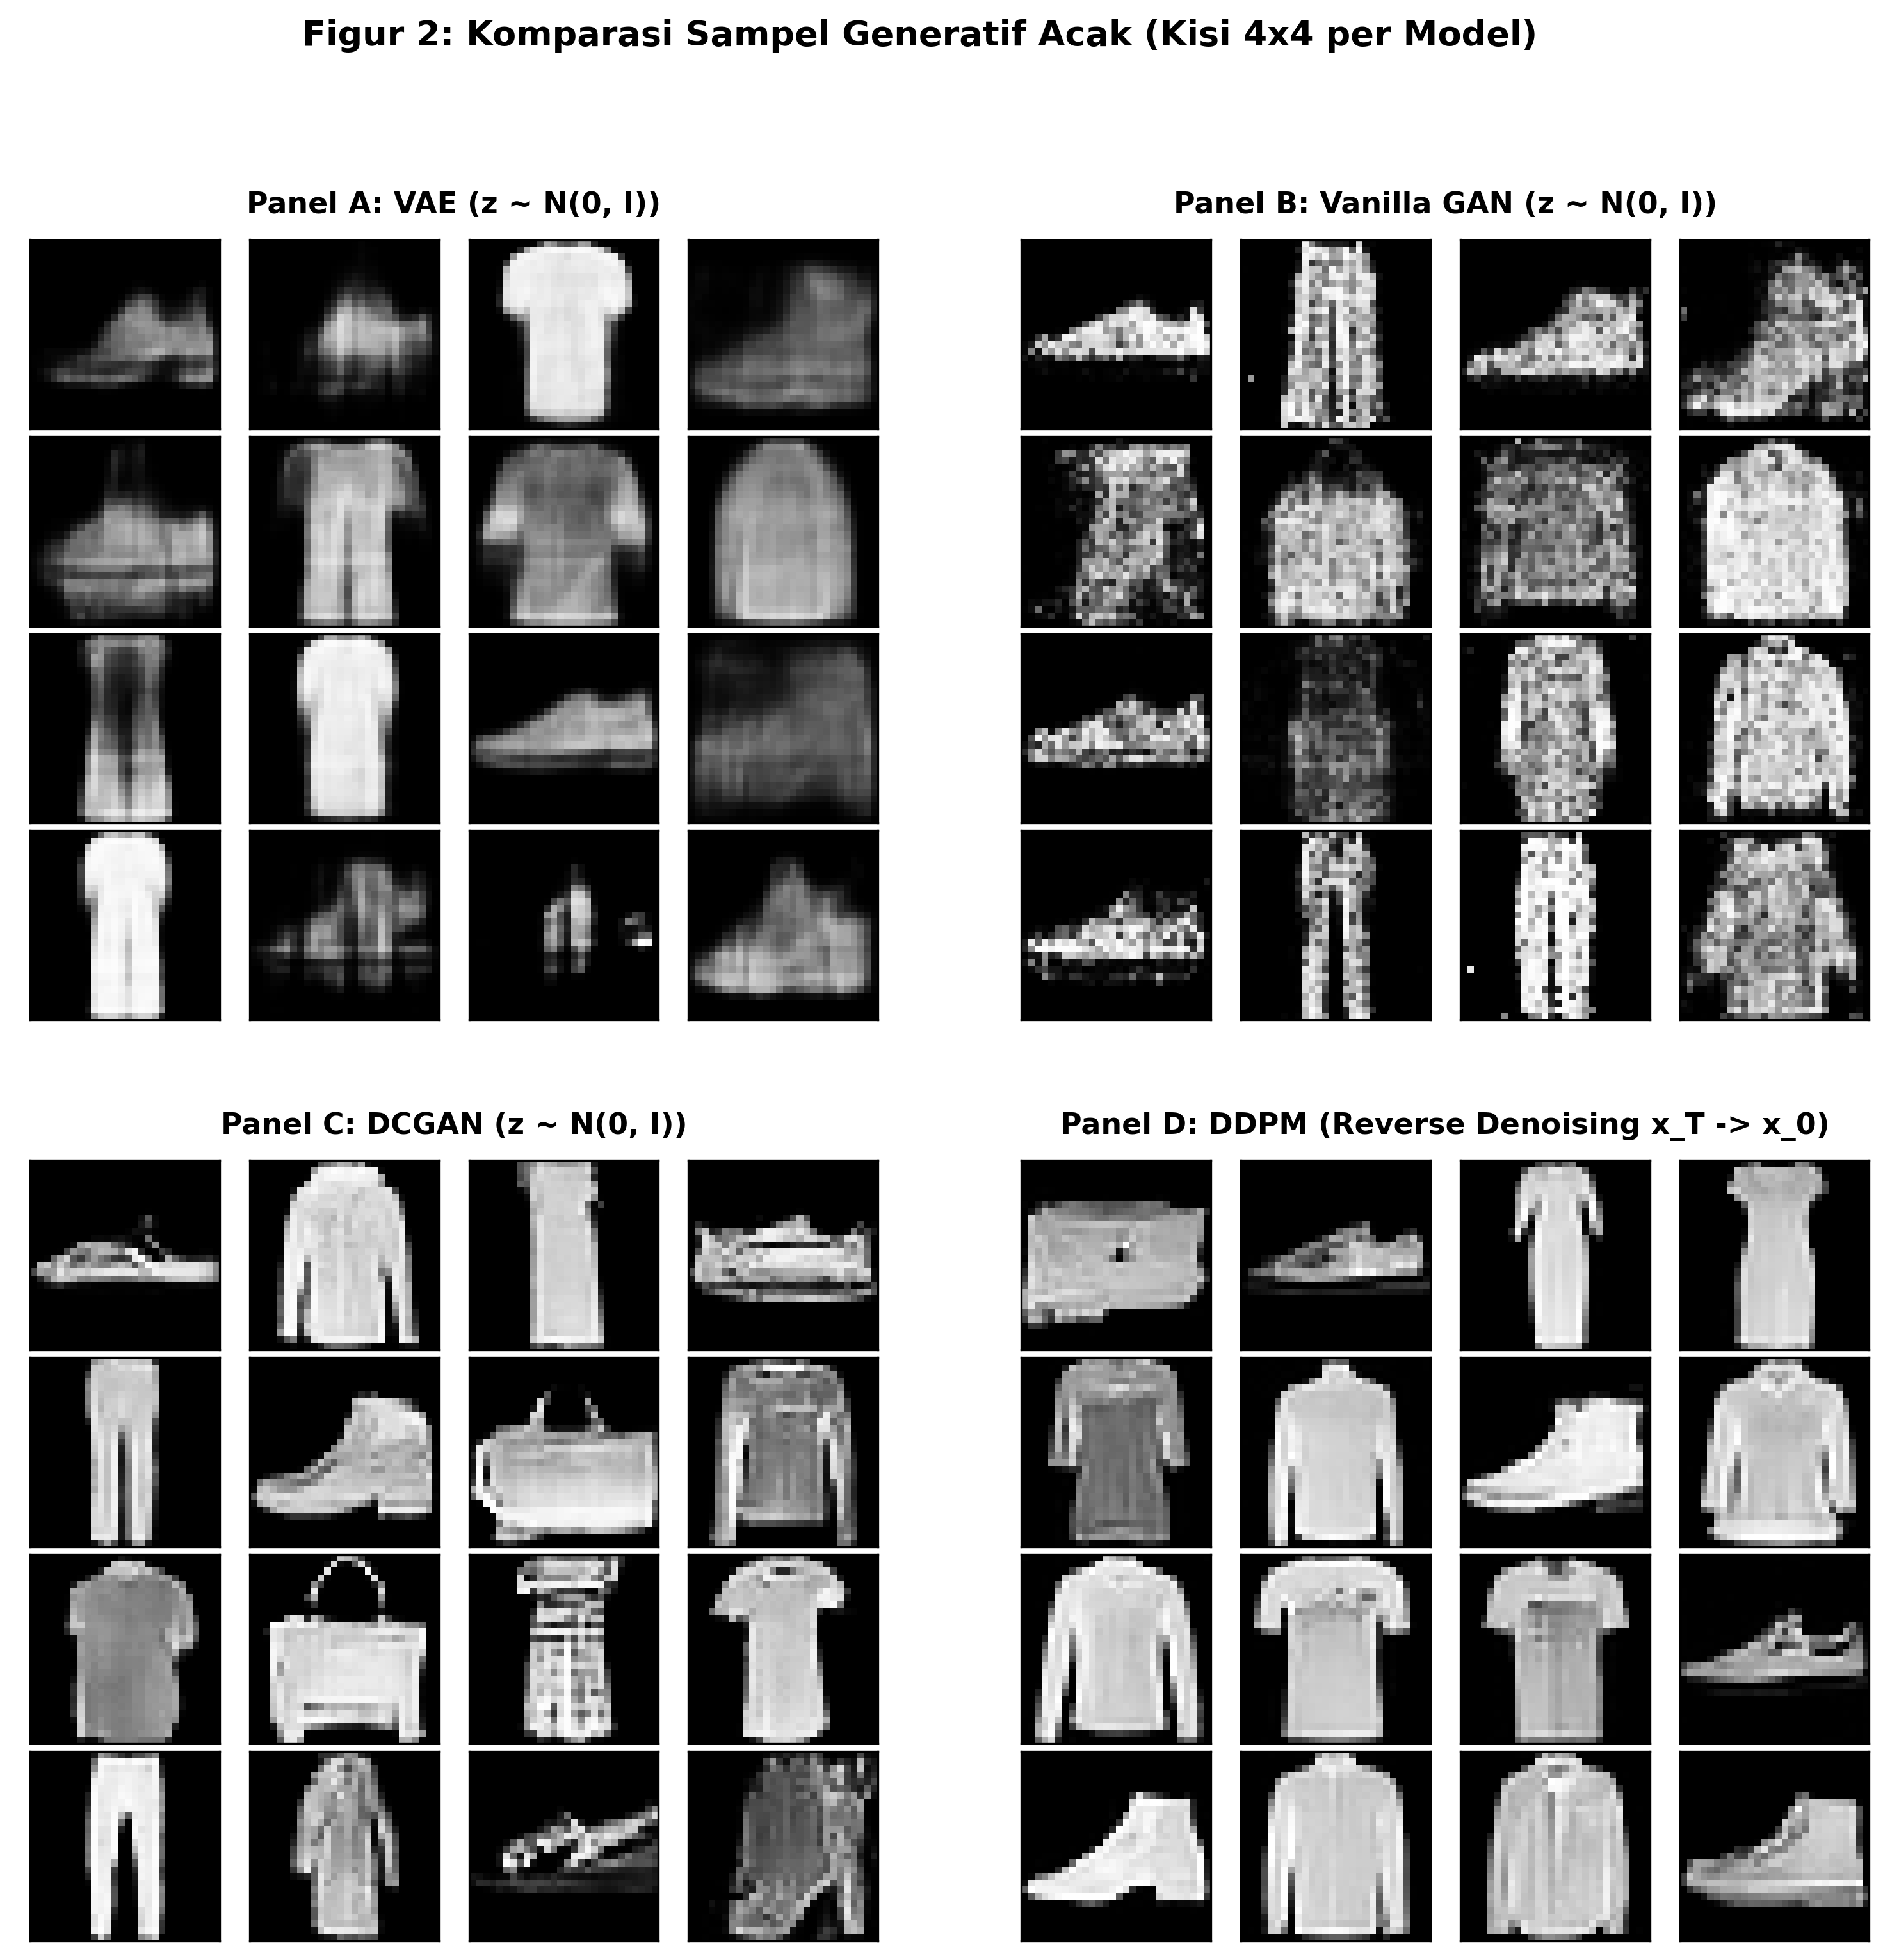

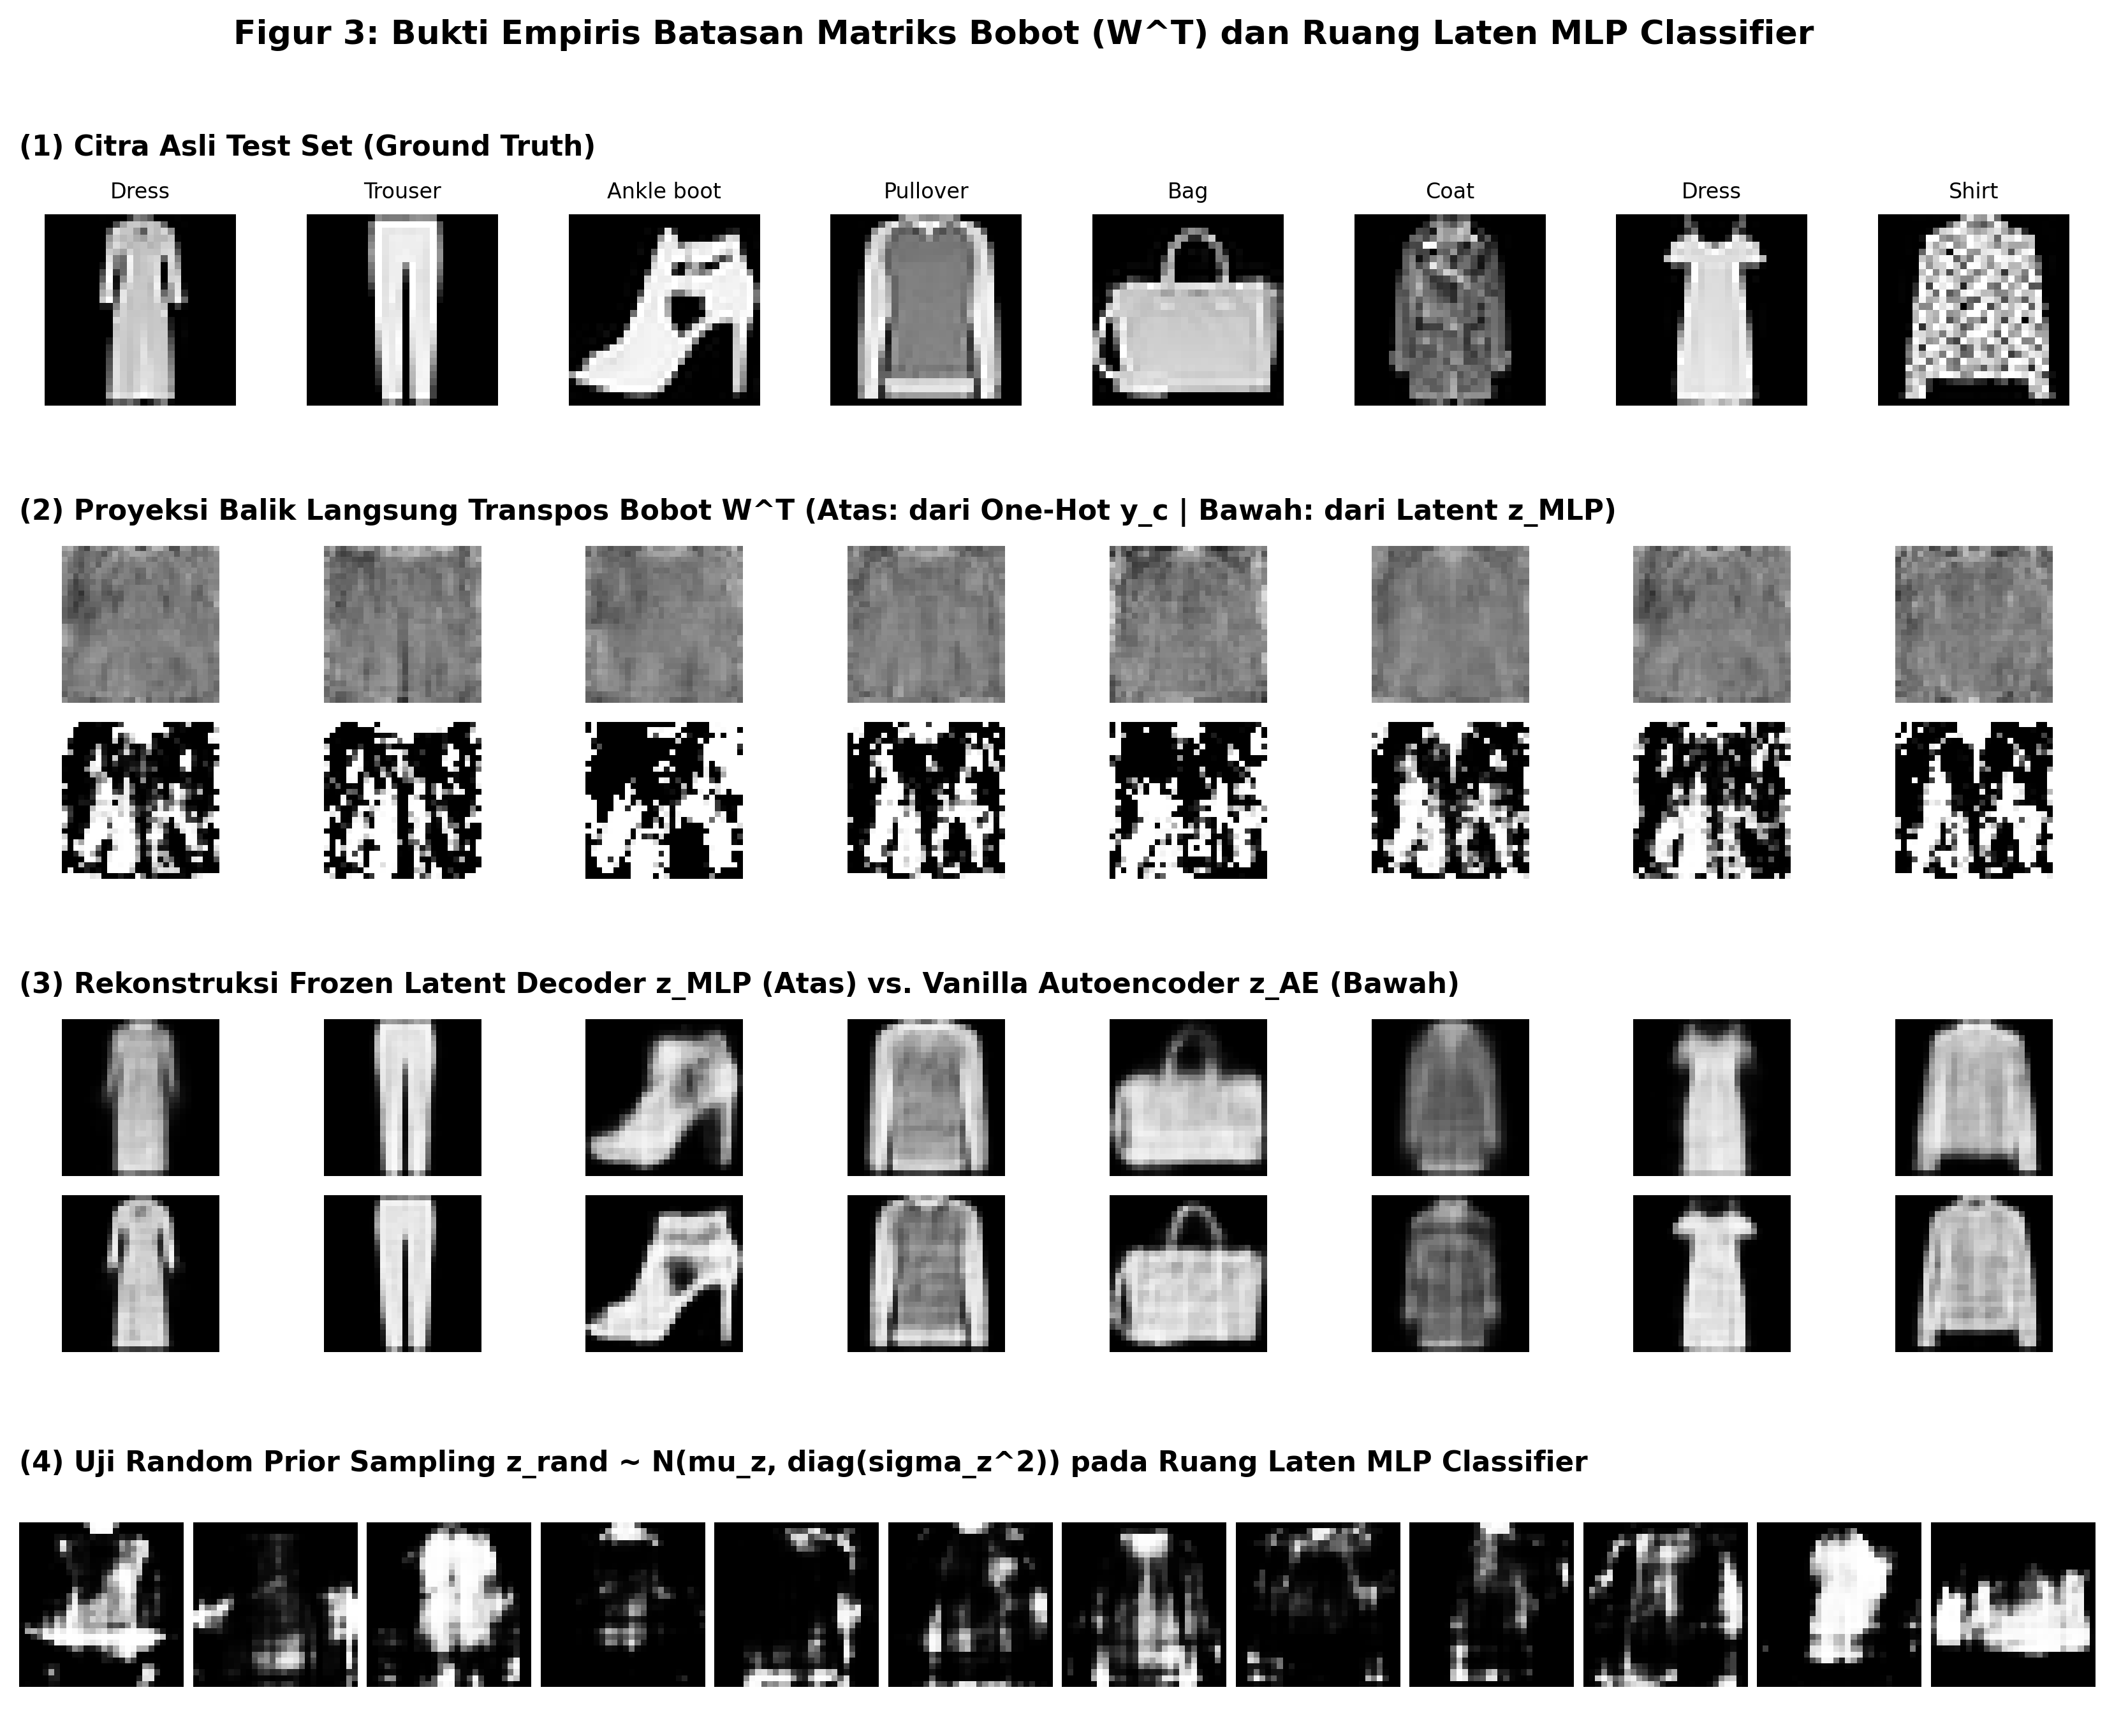

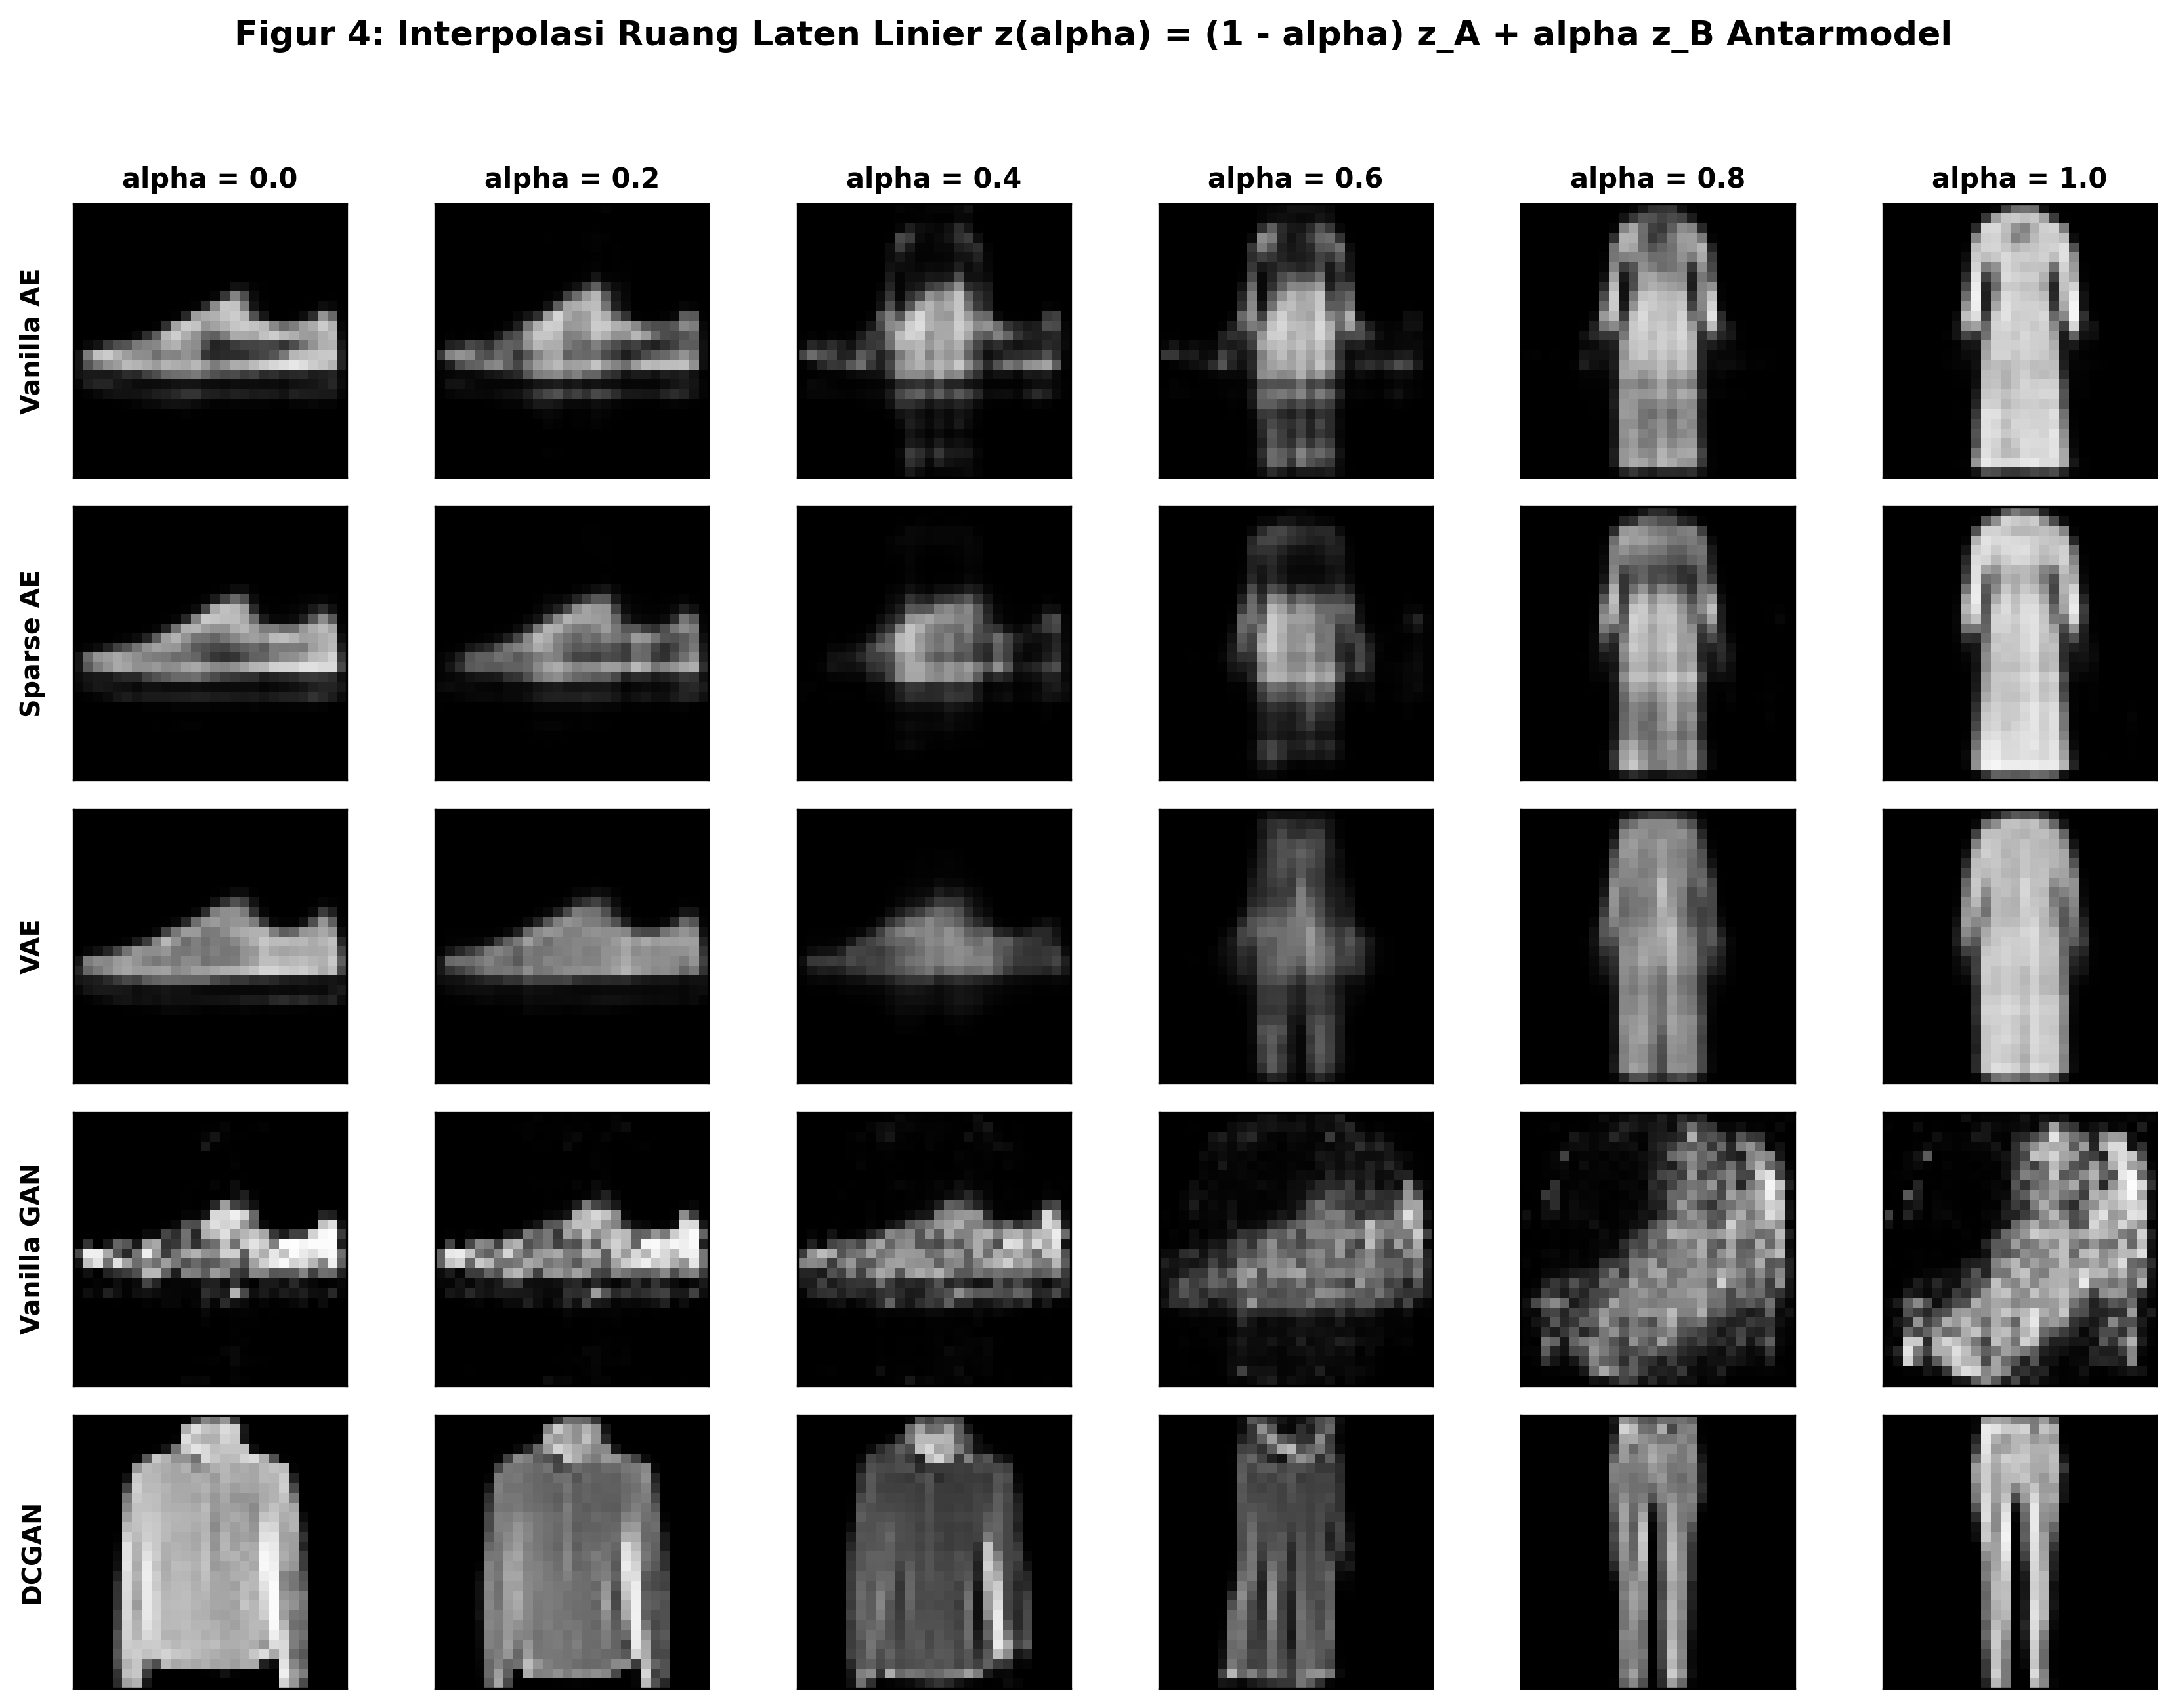

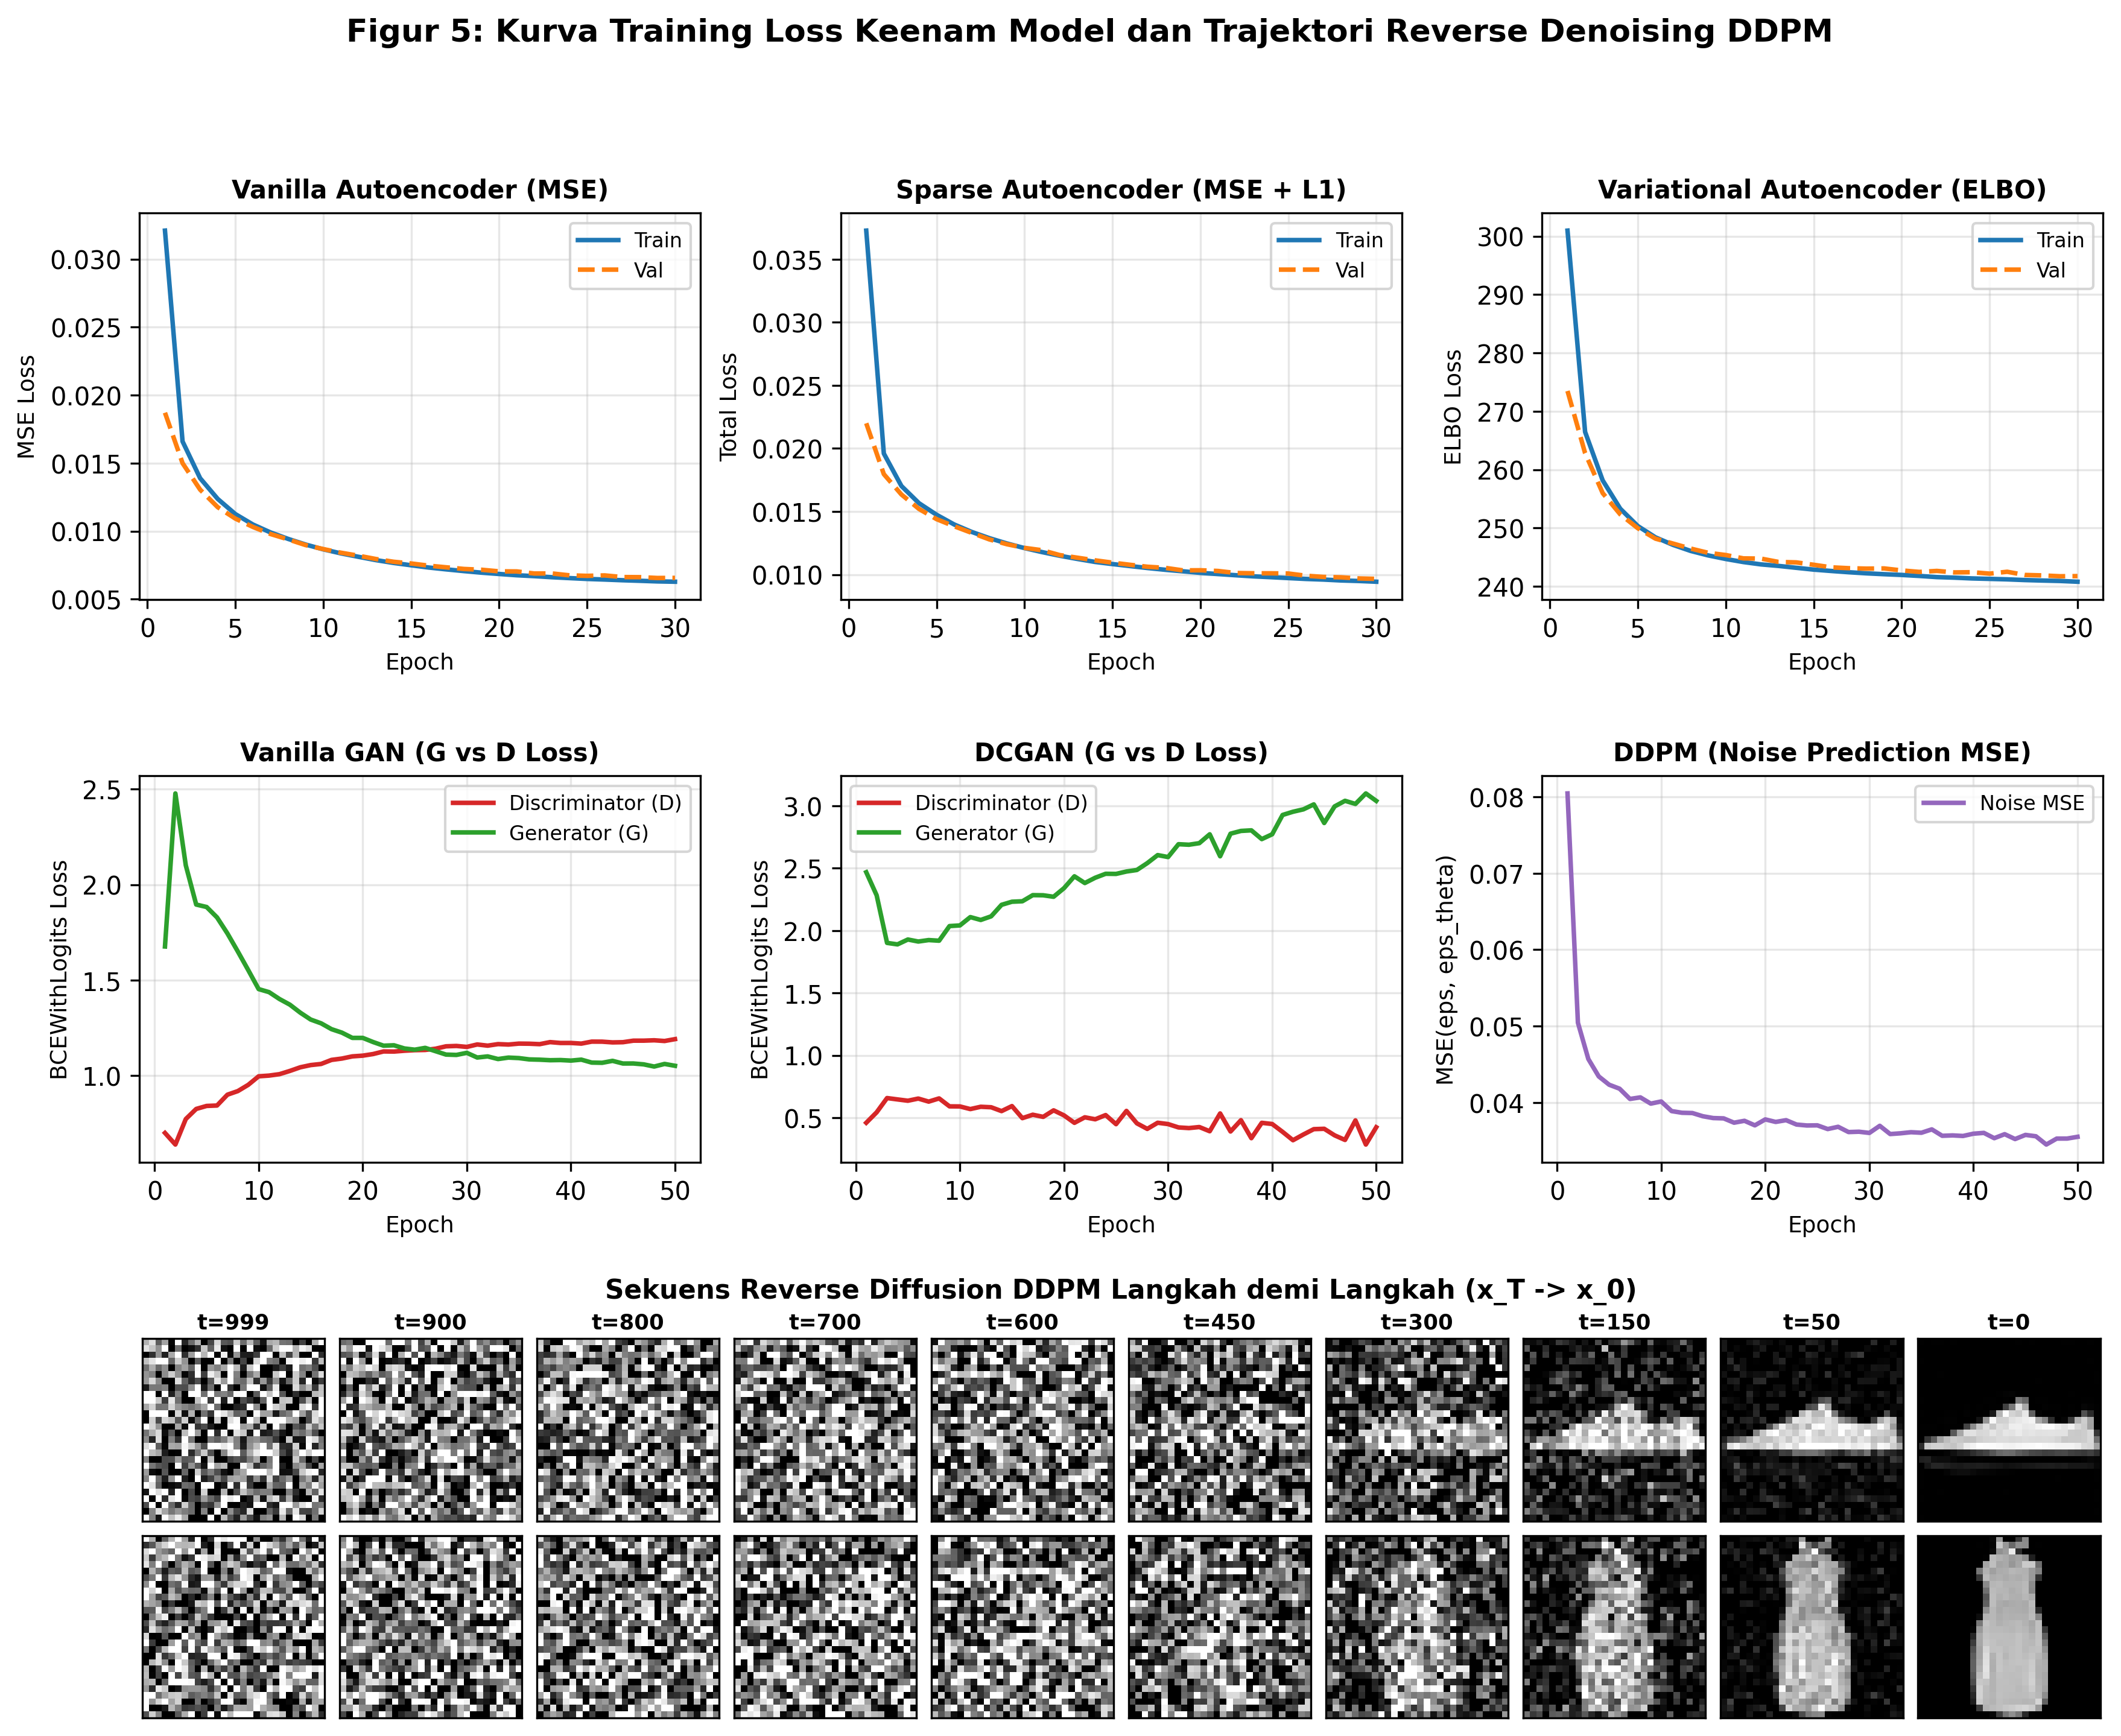

In [4]:
fig_files = [
    "fig1_reconstruction_grid.png",
    "fig2_generative_sampling_4x4.png",
    "fig3_mlp_limitation_proof.png",
    "fig4_latent_interpolation.png",
    "fig5_loss_curves_and_ddpm_trajectory.png",
]
for fname in fig_files:
    fpath = cfg.figures_dir / fname
    if fpath.exists():
        display(Image(filename=str(fpath)))